# 02 – Rozdelenie a baseline (FRD, TF-IDF + logistická regresia)

- čistenie: presné duplicity, biele znaky
- rozdelenie train / val / test 70 / 15 / 15, stratifikované podľa kategórie × label
- baseline len z textu (`text_`): TF-IDF slovné 1–2-gramy + logistická regresia
- model len z formálnych artefaktov (bez obsahu textu) – koľko úlohy vyriešia artefakty generovania
- kategória × kategória: train na jednej kategórii, test na každej (analógia generátor × generátor vo FraudSquad)

Vstup modelu je iba text. `rating` a `category` sa ako vstup nepoužívajú (sú vyvážené medzi triedami, ale neboli by dostupné pri všeobecnej detekcii).

In [1]:
from pathlib import Path

DATA_PATH = Path("../../data/FRD/fake reviews dataset.csv")
RESULTS = Path("../../results")
COL = {"text": "text_", "rating": "rating", "category": "category", "label": "label"}
LABEL_MAP = {"OR": 0, "CG": 1}

SEED = 42
VAL_FRAC = 0.15
TEST_FRAC = 0.15
DEDUP = True    # vyhodiť presné duplicity textu

In [2]:
import re
import numpy as np
import pandas as pd
from IPython.display import display

df = pd.read_csv(DATA_PATH)
txt, cat = COL["text"], COL["category"]
df["y"] = df[COL["label"]].map(LABEL_MAP)
df["cat"] = df[cat].str.replace(r"_5$", "", regex=True)   # kratšie názvy kategórií
print(df.shape)

(40432, 6)


## 1. Čistenie
- `strip()` textu
- deduplikácia podľa textu (`DEDUP`); duplicity sú len v rámci triedy, ale v train aj test by skresľovali evaluáciu

In [3]:
n0 = len(df)
df[txt] = df[txt].astype(str).str.strip()
df = df[df[txt] != ""]
if DEDUP:
    df = df.drop_duplicates(subset=[txt])
df = df.reset_index(drop=True)
print(f"pôvodne {n0} -> {len(df)}")
print(df["y"].value_counts().to_dict())

pôvodne 40432 -> 40410
{0: 20215, 1: 20195}


## 2. Rozdelenie
- stratifikácia podľa kategórie × label -> rovnaký podiel CG a rovnaké zastúpenie kategórií vo všetkých častiach

In [4]:
from sklearn.model_selection import train_test_split

strat = df["cat"] + "_" + df["y"].astype(str)
idx_trval, idx_test = train_test_split(df.index, test_size=TEST_FRAC, stratify=strat, random_state=SEED)
idx_train, idx_val = train_test_split(idx_trval, test_size=VAL_FRAC / (1 - TEST_FRAC),
                                      stratify=strat[idx_trval], random_state=SEED)
df["split"] = "train"
df.loc[idx_val, "split"] = "val"
df.loc[idx_test, "split"] = "test"

display(pd.crosstab(df["split"], df["y"], margins=True))
display(pd.crosstab(df["cat"], df["split"]))

y,0,1,All
split,,,
test,3033,3029,6062
train,14150,14136,28286
val,3032,3030,6062
All,20215,20195,40410


split,test,train,val
cat,,,
Books,656,3057,656
Clothing_Shoes_and_Jewelry,577,2691,577
Electronics,598,2792,598
Home_and_Kitchen,608,2839,608
Kindle_Store,709,3309,709
Movies_and_TV,538,2509,538
Pet_Supplies,638,2975,638
Sports_and_Outdoors,591,2760,592
Tools_and_Home_Improvement,578,2701,578


## 3. Baseline: TF-IDF + logistická regresia
- TF-IDF: slovné 1–2-gramy, `min_df=3`, `sublinear_tf=True` (rovnako ako FraudSquad 02)
- triedy sú vyvážené -> accuracy je informatívna; PR-AUC má náhodnú úroveň 0,5 (nie ~0,04 ako vo FraudSquad)
- prah 0,5 aj prah z validácie (maximum F1)

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, average_precision_score,
                             roc_auc_score, roc_curve, precision_recall_curve, confusion_matrix)

def part(split, cats=None):
    d = df[df["split"] == split]
    if cats is not None:
        d = d[d["cat"].isin(cats)]
    return d[txt].values, d["y"].values

def best_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr * rc / np.maximum(pr + rc, 1e-12)
    return th[np.argmax(f1[:-1])]

def recall_at_fpr(y, p, fpr_max=0.01):
    fpr, tpr, _ = roc_curve(y, p)
    return tpr[fpr <= fpr_max].max()

def metrics(y, p, thr=0.5):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p >= thr, average="binary", zero_division=0)
    return dict(accuracy=accuracy_score(y, p >= thr), precision=pr, recall=rc, f1=f1,
                pr_auc=average_precision_score(y, p), roc_auc=roc_auc_score(y, p),
                recall_at_fpr1=recall_at_fpr(y, p), thr=thr, n_test=len(y), base_rate=y.mean())

Xtr, ytr = part("train"); Xva, yva = part("val"); Xte, yte = part("test")
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True)
clf = LogisticRegression(max_iter=2000, C=1.0)
clf.fit(vec.fit_transform(Xtr), ytr)
p_va = clf.predict_proba(vec.transform(Xva))[:, 1]
p_te = clf.predict_proba(vec.transform(Xte))[:, 1]
thr = best_threshold(yva, p_va)

res = pd.DataFrame([dict(model="tfidf_word_lr", prah="0.5", **metrics(yte, p_te, 0.5)),
                    dict(model="tfidf_word_lr", prah="z validácie", **metrics(yte, p_te, thr))])
display(res.round(3))
print("matica zámen (prah 0.5), riadky = skutočnosť [OR, CG]:")
print(confusion_matrix(yte, p_te >= 0.5))

,model,prah,accuracy,precision,recall,f1,pr_auc,roc_auc,recall_at_fpr1,thr,n_test,base_rate
0,tfidf_word_lr,0.5,0.928,0.947,0.908,0.927,0.982,0.981,0.778,0.500,6062,0.5
1,tfidf_word_lr,z validácie,0.930,0.929,0.932,0.930,0.982,0.981,0.778,0.453,6062,0.5


matica zámen (prah 0.5), riadky = skutočnosť [OR, CG]:
[[2878  155]
 [ 280 2749]]


In [6]:
# Výsledok po kategóriách (test)
te = df[df["split"] == "test"].assign(p=p_te)
display(te.groupby("cat").apply(lambda g: pd.Series({"n": len(g),
        "accuracy": accuracy_score(g["y"], g["p"] >= 0.5),
        "roc_auc": roc_auc_score(g["y"], g["p"])}), include_groups=False).round(3))

,n,accuracy,roc_auc
cat,,,
Books,656.0,0.905,0.971
Clothing_Shoes_and_Jewelry,577.0,0.927,0.979
Electronics,598.0,0.941,0.985
Home_and_Kitchen,608.0,0.939,0.985
Kindle_Store,709.0,0.929,0.982
Movies_and_TV,538.0,0.911,0.980
Pet_Supplies,638.0,0.933,0.984
Sports_and_Outdoors,591.0,0.937,0.986
Tools_and_Home_Improvement,578.0,0.938,0.983


## 4. Model len z formálnych artefaktov
- príznaky bez obsahu: dĺžka (slová, znaky), koniec interpunkciou, počet spojení viet bez medzery, dvojité medzery, nové riadky, číslice, `...`, `!`, podiel veľkých písmen, priemerná dĺžka slova a vety
- `HistGradientBoostingClassifier` (zachytí aj nelineárne vzťahy, napr. pásma dĺžky)
- ak tento model dosiahne vysoké ROC-AUC, časť výkonu baseline pochádza z artefaktov generovania, nie zo štýlu textu

In [7]:
from sklearn.ensemble import HistGradientBoostingClassifier

END_RE = re.compile(r"[.!?\"')\]]\s*$")
JOIN_RE = re.compile(r"[a-z0-9)][.!?][A-Z]")

def artifact_features(texts):
    s = pd.Series(texts, dtype=str)
    words = s.str.split()
    n_w = words.str.len()
    n_sent = s.str.count(r"[.!?]+") + 1
    return pd.DataFrame({
        "n_words": n_w,
        "n_chars": s.str.len(),
        "ends_punct": s.str.contains(END_RE).astype(int),
        "n_joins": s.str.count(JOIN_RE),
        "n_double_space": s.str.count("  "),
        "n_newline": s.str.count("\n"),
        "n_digits": s.str.count(r"\d"),
        "n_ellipsis": s.str.count(r"\.\.\."),
        "n_excl": s.str.count("!"),
        "upper_ratio": s.str.count(r"[A-Z]") / s.str.len().clip(lower=1),
        "mean_word_len": s.str.replace(r"\s+", "", regex=True).str.len() / n_w.clip(lower=1),
        "words_per_sent": n_w / n_sent,
    })

Ftr, Fva, Fte = artifact_features(Xtr), artifact_features(Xva), artifact_features(Xte)
art = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, random_state=SEED).fit(Ftr, ytr)
p_art = art.predict_proba(Fte)[:, 1]
res_art = pd.DataFrame([dict(model="artefakty_hgb", prah="0.5", **metrics(yte, p_art, 0.5))])
display(res_art.round(3))

# Jednotlivé príznaky: ROC-AUC (smer zarovnaný na >= 0.5)
auc = {c: roc_auc_score(yte, Fte[c]) for c in Fte}
display(pd.Series({c: max(a, 1 - a) for c, a in auc.items()}).sort_values(ascending=False).round(3).to_frame("ROC-AUC"))

,model,prah,accuracy,precision,recall,f1,pr_auc,roc_auc,recall_at_fpr1,thr,n_test,base_rate
0,artefakty_hgb,0.5,0.872,0.891,0.847,0.868,0.954,0.949,0.587,0.5,6062,0.5


,ROC-AUC
ends_punct,0.781
mean_word_len,0.719
n_joins,0.645
upper_ratio,0.559
n_chars,0.555
words_per_sent,0.554
n_digits,0.551
n_ellipsis,0.542
n_excl,0.540
n_double_space,0.540


In [8]:
# Permutačná dôležitosť príznakov artefaktového modelu
from sklearn.inspection import permutation_importance
imp = permutation_importance(art, Fte, yte, scoring="roc_auc", n_repeats=5, random_state=SEED)
display(pd.Series(imp.importances_mean, index=Fte.columns).sort_values(ascending=False).round(3).to_frame("pokles ROC-AUC"))

,pokles ROC-AUC
ends_punct,0.121
n_joins,0.119
mean_word_len,0.048
words_per_sent,0.044
n_words,0.033
n_excl,0.013
n_chars,0.012
n_ellipsis,0.010
n_double_space,0.009
upper_ratio,0.006


## 5. Kategória × kategória
- train na jednej kategórii (train časť), test na každej kategórii (test časť)
- diagonála: tá istá kategória; mimo diagonály: neznáma kategória
- metrika: ROC-AUC (triedy vyvážené, PR-AUC by dávalo podobný obraz)

In [9]:
CATS = sorted(df["cat"].unique())
rows = []
for c_tr in CATS:
    Xa, ya = part("train", [c_tr])
    v = TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True)
    m = LogisticRegression(max_iter=2000).fit(v.fit_transform(Xa), ya)
    for c_te in CATS:
        Xb, yb = part("test", [c_te])
        p = m.predict_proba(v.transform(Xb))[:, 1]
        rows.append(dict(train=c_tr, test=c_te, **metrics(yb, p)))
cc = pd.DataFrame(rows)
mat = cc.pivot(index="train", columns="test", values="roc_auc")
display(mat.round(3))

diag = np.diag(mat.values)
off = mat.values[~np.eye(len(CATS), dtype=bool)]
print(f"ROC-AUC diagonála: priemer {diag.mean():.3f} (min {diag.min():.3f}, max {diag.max():.3f})")
print(f"ROC-AUC mimo diagonály: priemer {off.mean():.3f} (min {off.min():.3f}, max {off.max():.3f})")

test,Books,Clothing_Shoes_and_Jewelry,Electronics,Home_and_Kitchen,Kindle_Store,Movies_and_TV,Pet_Supplies,Sports_and_Outdoors,Tools_and_Home_Improvement,Toys_and_Games
train,,,,,,,,,,
Books,0.972,0.879,0.899,0.920,0.970,0.960,0.909,0.887,0.914,0.888
Clothing_Shoes_and_Jewelry,0.857,0.968,0.920,0.936,0.867,0.888,0.915,0.930,0.935,0.871
Electronics,0.879,0.926,0.972,0.955,0.867,0.922,0.947,0.957,0.957,0.908
Home_and_Kitchen,0.879,0.930,0.951,0.976,0.876,0.906,0.955,0.949,0.955,0.920
Kindle_Store,0.955,0.837,0.872,0.867,0.974,0.941,0.863,0.869,0.876,0.848
Movies_and_TV,0.939,0.902,0.900,0.916,0.949,0.979,0.908,0.904,0.916,0.879
Pet_Supplies,0.892,0.929,0.942,0.956,0.893,0.921,0.977,0.956,0.953,0.920
Sports_and_Outdoors,0.885,0.954,0.960,0.968,0.899,0.924,0.961,0.975,0.960,0.921
Tools_and_Home_Improvement,0.897,0.940,0.960,0.963,0.907,0.925,0.948,0.950,0.971,0.934


ROC-AUC diagonála: priemer 0.972 (min 0.963, max 0.979)
ROC-AUC mimo diagonály: priemer 0.918 (min 0.837, max 0.970)


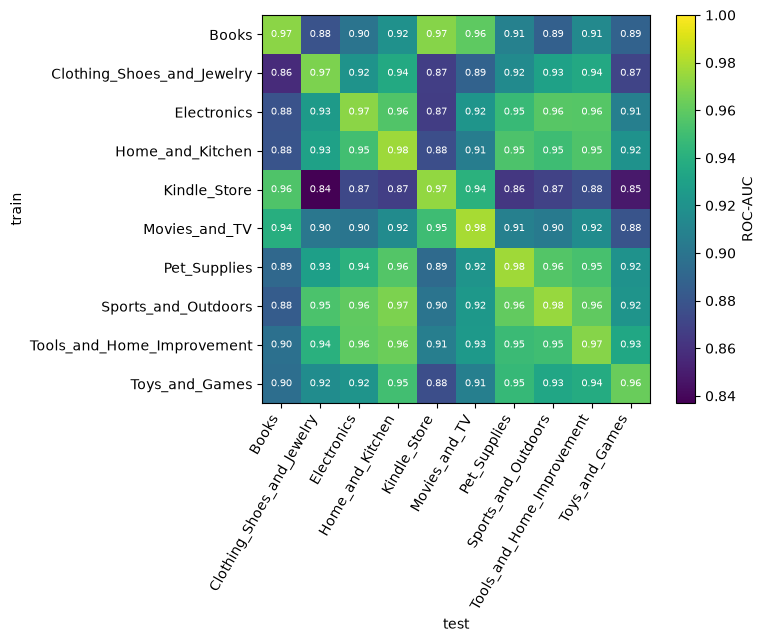

In [10]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(mat.values, cmap="viridis", vmin=mat.values.min(), vmax=1)
ax.set_xticks(range(len(CATS)), CATS, rotation=60, ha="right"); ax.set_yticks(range(len(CATS)), CATS)
ax.set_xlabel("test"); ax.set_ylabel("train")
for i in range(len(CATS)):
    for j in range(len(CATS)):
        ax.text(j, i, f"{mat.values[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w")
fig.colorbar(im, ax=ax, label="ROC-AUC")
plt.tight_layout(); plt.show()

## 6. Uloženie výsledkov

In [11]:
RESULTS.mkdir(exist_ok=True)
out = pd.concat([res, res_art, cc.assign(model="tfidf_word_lr_cat", prah="0.5")], ignore_index=True)
out.to_csv(RESULTS / "frd_baseline.csv", index=False)
print("uložené:", RESULTS / "frd_baseline.csv", out.shape)

uložené: ../../results/frd_baseline.csv (103, 14)


## Výsledok
- čistenie: 40 432 -> 40 410 recenzií (22 duplicít a prázdnych); rozdelenie (seed 42): train 28 286, val 6 062, test 6 062, podiel CG 0,5
- TF-IDF + LR: accuracy 0,928, F1 0,927, ROC-AUC 0,981 (prah 0,5); prah z validácie (0,453) mení výsledok minimálne; recall pri FPR 1 % len 0,778
- kategórie: ROC-AUC 0,971 (Books) – 0,986 (Sports_and_Outdoors)
- **model len z artefaktov (bez obsahu): ROC-AUC 0,949, accuracy 0,872** -> veľká časť úlohy je riešiteľná bez čítania obsahu
  - najdôležitejšie príznaky: koniec interpunkciou, spojenie viet bez medzery (pokles ROC-AUC 0,12 po permutácii), potom priemerná dĺžka slova a dĺžka vety
- kategória × kategória: ROC-AUC diagonála 0,972, mimo diagonály 0,918 (min 0,837: Kindle_Store -> Clothing); prenos je lepší medzi podobnými doménami (Books ↔ Kindle_Store ↔ Movies_and_TV, produktové kategórie medzi sebou)